
# 🧬 TASK B — DNA Fragmentation Classification qua Halo Size (Multiclass)

**Dataset:** *Expert-Annotated Optical Microscopy Images of Human Sperm for Detection and DNA Fragmentation Assessment* (Saadat, Borna & Torkashvand, Scientific Data 2026) — Figshare DOI: `10.6084/m9.figshare.30120811`

Notebook này huấn luyện & so sánh các **teacher model** cho bài toán phân loại đa lớp mức độ đứt gãy DNA dựa trên kích thước quầng halo (large / medium / small / no halo — theo bài báo là 403 ảnh; thư mục thực tế trên Figshare **có thể có thêm lớp phụ**, notebook sẽ tự dò và in ra để bạn xác nhận).

**Các model benchmark trong notebook này:** `resnet50`, `convnext_base`, `efficientnetv2_m`, `swin_base`, `vit_base`, `dinov2`

### Quyết định thiết kế đã chốt
| Vấn đề | Quyết định |
|---|---|
| Chia dữ liệu | Hold-out cố định **70/15/15** (stratified theo lớp), chia **một lần duy nhất**, lưu vào `data/taskB_split.json` trên Drive — mọi lần chạy sau (kể cả notebook Evaluation) đều load lại đúng file này |
| Preprocessing | Không cần tiền xử lý nặng; chỉ resize/normalize theo từng model + augmentation nhẹ, **cẩn trọng không crop mất viền halo** (đặc trưng quyết định nhãn!) |
| Fine-tuning (5 model CNN/Transformer thường) | **2-Stage**: Stage 1 đóng băng backbone train head → Stage 2 mở toàn bộ, fine-tune LR rất nhỏ (discriminative LR) |
| Fine-tuning riêng cho **DINOv2** | **Linear probing**: đóng băng toàn bộ backbone self-supervised, chỉ train classifier head — đây là cách dùng chuẩn/khuyến nghị cho DINOv2, tránh phá vỡ biểu diễn đã học trên bộ dữ liệu quá nhỏ |
| Early Stopping | Theo dõi **Macro-F1 trên tập validation** |
| Idempotency | Tự kiểm tra tồn tại dữ liệu / split trước khi làm lại — an toàn khi chạy ngắt quãng nhiều ngày hoặc nhiều model song song |

⚠️ **Lưu ý quan trọng:** Notebook này **CHỈ dùng tập train + val**. Tập test được giữ tách biệt hoàn toàn, chỉ dùng trong notebook `Evaluation.ipynb`.


## 1. Cài đặt thư viện

In [1]:

!pip install -q timm==1.0.11 scikit-learn seaborn


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.4/48.4 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 37.7 MB/s eta 0:00:00


## 2. Import & thiết lập seed / device

In [2]:

import os, sys, json, time, random, shutil, zipfile, glob, copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
from timm.data import resolve_data_config
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, confusion_matrix, classification_report)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Thiết bị đang sử dụng: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Thiết bị đang sử dụng: cuda
GPU: Tesla T4


## 3. Kết nối Google Drive & định nghĩa đường dẫn

In [3]:

from google.colab import drive
drive.mount('/content/drive')

DRIVE_ROOT       = "/content/drive/MyDrive/SpermAI_Benchmark"
DATA_DRIVE_DIR   = f"{DRIVE_ROOT}/data"            # cache zip gốc + file chia tập cố định (dùng chung Task A & B)
OUTPUT_DRIVE_DIR = f"{DRIVE_ROOT}/outputs/TaskB"   # kết quả của từng model trong Task B
os.makedirs(DATA_DRIVE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DRIVE_DIR, exist_ok=True)

LOCAL_ROOT   = "/content/sperm_data"
RAW_ROOT     = f"{LOCAL_ROOT}/raw_extracted"
RAW_ZIP_PATH = f"{LOCAL_ROOT}/dataset_download.zip"
os.makedirs(LOCAL_ROOT, exist_ok=True)

print("DATA_DRIVE_DIR  :", DATA_DRIVE_DIR)
print("OUTPUT_DRIVE_DIR:", OUTPUT_DRIVE_DIR)


Mounted at /content/drive
DATA_DRIVE_DIR  : /content/drive/MyDrive/SpermAI_Benchmark/data
OUTPUT_DRIVE_DIR: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskB



## 4. Tải & giải nén dataset (idempotent)

Ưu tiên dữ liệu đã có sẵn trong phiên Colab → Figshare → cache trên Drive.


In [5]:
import subprocess

FIGSHARE_ARTICLE_ID   = "30120811"
FIGSHARE_DOWNLOAD_URL = f"https://ndownloader.figshare.com/articles/{FIGSHARE_ARTICLE_ID}/versions/1"
DRIVE_CACHED_ZIP      = f"{DATA_DRIVE_DIR}/figshare_raw_dataset.zip"

def _find_dir(root, keyword):
    """Tìm (đệ quy) thư mục có tên chứa `keyword` (không phân biệt hoa/thường)."""
    keyword = keyword.lower()
    for dirpath, dirnames, _ in os.walk(root):
        for d in dirnames:
            if keyword in d.lower():
                return os.path.join(dirpath, d)
    return None

def _extract_recursive(zip_path, dest):
    """Giải nén archive Figshare bằng unrar.
    File Figshare có thể mang đuôi .zip nhưng thực tế chứa archive RAR
    (bên trong có Dataset/ và các thư mục dữ liệu thật)."""
    result = subprocess.run(
        ["unrar", "x", "-o+", "-p-", zip_path, dest + "/"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
        text=True
    )

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError("Giải nén archive thất bại.")

def dataset_is_ready(root):
    """Dữ liệu thô được coi là sẵn sàng khi tìm thấy cả 2 thư mục nhãn gốc."""
    bin_dir  = _find_dir(root, "Binary Classification")
    halo_dir = _find_dir(root, "Halo Classification")
    ok = bool(bin_dir) and bool(halo_dir)
    if ok:
        print(f"  ✓ Tìm thấy: {bin_dir}")
        print(f"  ✓ Tìm thấy: {halo_dir}")
    return ok

if dataset_is_ready(RAW_ROOT):
    # ƯU TIÊN 1: dữ liệu đã có sẵn trong phần cứng Colab (phiên hiện tại) -> dùng chung, không tải lại
    print("✅ Dữ liệu thô đã có sẵn trong phần cứng Colab (phiên hiện tại) — bỏ qua tải & giải nén (dùng chung giữa các model).")
else:
    os.makedirs(RAW_ROOT, exist_ok=True)
    downloaded = False

    # ƯU TIÊN 2: đã có bản zip cache trên Google Drive (từ lần chạy trước, tự động HOẶC bạn tự upload thủ công)
    if os.path.exists(DRIVE_CACHED_ZIP):
        print("⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).")
        shutil.copy(DRIVE_CACHED_ZIP, RAW_ZIP_PATH)
        downloaded = True
    else:
        # ƯU TIÊN 3 (chỉ xảy ra ở LẦN CHẠY ĐẦU TIÊN, khi Drive chưa có gì): tải từ Figshare
        print("⬇️  Chưa có bản cache trên Drive — đang tải dataset từ Figshare (chỉ xảy ra ở lần đầu tiên) ...")
        try:
            import urllib.request
            urllib.request.urlretrieve(FIGSHARE_DOWNLOAD_URL, RAW_ZIP_PATH)
            if os.path.getsize(RAW_ZIP_PATH) > 10_000:
                downloaded = True
        except Exception as e:
            print(f"  ✗ Tải từ Figshare thất bại: {e}")

    if not downloaded:
        raise RuntimeError(
            "Không thể tải dataset tự động (không có cache trên Drive, và tải từ Figshare thất bại).\n"
            "→ Hãy tải thủ công file zip tại https://doi.org/10.6084/m9.figshare.30120811,\n"
            f"  upload lên Google Drive đúng đường dẫn: {DRIVE_CACHED_ZIP}\n"
            "  rồi chạy lại cell này."
        )

    print("📦 Đang giải nén ...")
    _extract_recursive(RAW_ZIP_PATH, RAW_ROOT)

    if not dataset_is_ready(RAW_ROOT):
        raise RuntimeError(
            "Giải nén xong nhưng KHÔNG tìm thấy thư mục 'Binary Classification' hoặc 'Halo Classification'.\n"
            "→ Hãy kiểm tra thủ công cấu trúc bên trong RAW_ROOT (dùng lệnh !find) và chỉnh lại hàm _find_dir nếu tên khác."
        )

    # Nếu zip này vừa được tải MỚI từ Figshare (Drive lúc nãy chưa có) -> tự backup lên Drive cho các lần sau.
    # Nếu bạn muốn tự kiểm soát bản cache (tự nén thủ công), chỉ cần upload file của bạn đúng path
    # DRIVE_CACHED_ZIP trước khi chạy cell này — code sẽ ưu tiên dùng bản đó và bỏ qua bước tải Figshare.
    if not os.path.exists(DRIVE_CACHED_ZIP):
        print("☁️  Sao lưu zip gốc lên Drive để các lần chạy sau không cần tải lại từ Figshare ...")
        shutil.copy(RAW_ZIP_PATH, DRIVE_CACHED_ZIP)

    print("✅ Hoàn tất tải & giải nén dataset.")

BINARY_DIR = _find_dir(RAW_ROOT, "Binary Classification")
HALO_DIR   = _find_dir(RAW_ROOT, "Halo Classification")   # không dùng ở Task A, chỉ in ra để kiểm tra
print("\nBINARY_DIR:", BINARY_DIR)
print("HALO_DIR  :", HALO_DIR, " (không dùng trong Task A)")

⬇️  Tìm thấy bản zip đã cache trên Google Drive → dùng bản này (KHÔNG tải lại từ Figshare).
📦 Đang giải nén ...
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Binary Classification
  ✓ Tìm thấy: /content/sperm_data/raw_extracted/Dataset/Halo Classification
✅ Hoàn tất tải & giải nén dataset.

BINARY_DIR: /content/sperm_data/raw_extracted/Dataset/Binary Classification
HALO_DIR  : /content/sperm_data/raw_extracted/Dataset/Halo Classification  (không dùng trong Task A)



## 5. Phát hiện danh sách lớp & liệt kê toàn bộ ảnh

⚠️ Bài báo mô tả 4 lớp (`LargeHalo, MediumHalo, SmallHalo, NoHalo`, tổng 403 ảnh) nhưng đoạn "Data Records" lại liệt kê **5 thư mục con** thực tế (`LargeHalo, MediumHalo, SmallHalo, NoHalo, NonSperm`). Vì vậy ta **tự động dò toàn bộ thư mục con thực tế** thay vì hard-code 4 lớp — hãy đọc kỹ output bên dưới để xác nhận đúng số lớp trước khi train.


In [6]:

TASK_RAW_DIR = HALO_DIR
assert TASK_RAW_DIR is not None, "Không tìm thấy thư mục dữ liệu Task B!"

CLASSES = sorted([
    d for d in os.listdir(TASK_RAW_DIR)
    if os.path.isdir(os.path.join(TASK_RAW_DIR, d))
    and d.lower() != "non-sperm"
])
print(f"Phát hiện {len(CLASSES)} lớp: {CLASSES}")
print("👉 Lớp 'Non-sperm' đã được loại bỏ khỏi dữ liệu Task B.")

IMG_EXTS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
samples = []
for cls in CLASSES:
    cls_dir = os.path.join(TASK_RAW_DIR, cls)
    files = sorted([f for f in os.listdir(cls_dir) if f.lower().endswith(IMG_EXTS)])
    for f in files:
        samples.append({"class": cls, "filename": f, "path": os.path.join(cls_dir, f)})

df_samples = pd.DataFrame(samples)
print("\nTổng số ảnh mỗi lớp:")
print(df_samples.groupby("class").size())
assert len(df_samples) > 0, "Không đọc được ảnh nào — kiểm tra lại đường dẫn TASK_RAW_DIR."

class_to_idx = {c: i for i, c in enumerate(CLASSES)}
print("\nclass_to_idx:", class_to_idx)


Phát hiện 4 lớp: ['Large halo', 'Medium halo', 'Small halo', 'Without halo']
👉 Lớp 'Non-sperm' đã được loại bỏ khỏi dữ liệu Task B.

Tổng số ảnh mỗi lớp:
class
Large halo      103
Medium halo     107
Small halo       92
Without halo    101
dtype: int64

class_to_idx: {'Large halo': 0, 'Medium halo': 1, 'Small halo': 2, 'Without halo': 3}



## 6. Chia train / val / test cố định (70/15/15, stratified)

Giống Task A: file `taskB_split.json` chỉ được tạo **1 lần duy nhất** rồi lưu Drive, mọi lần chạy sau load lại đúng file này.


In [7]:

SPLIT_JSON_DRIVE = f"{DATA_DRIVE_DIR}/taskB_split.json"
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15

if os.path.exists(SPLIT_JSON_DRIVE):
    print("📄 Đã có file chia tập trên Drive → dùng lại (đảm bảo nhất quán giữa các lần chạy).")
    with open(SPLIT_JSON_DRIVE, "r") as f:
        split_map = json.load(f)
else:
    print("✂️  Chưa có file chia tập → tạo mới (CHỈ diễn ra 1 LẦN DUY NHẤT cho toàn bộ benchmark Task B).")
    train_val, test = train_test_split(
        df_samples, test_size=TEST_RATIO, stratify=df_samples["class"], random_state=SEED
    )
    val_ratio_adj = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
    train, val = train_test_split(
        train_val, test_size=val_ratio_adj, stratify=train_val["class"], random_state=SEED
    )
    split_map = {
        "train": train[["class", "filename"]].values.tolist(),
        "val":   val[["class", "filename"]].values.tolist(),
        "test":  test[["class", "filename"]].values.tolist(),
    }
    with open(SPLIT_JSON_DRIVE, "w") as f:
        json.dump(split_map, f, indent=2)
    print(f"✅ Đã lưu file chia tập cố định tại: {SPLIT_JSON_DRIVE}")

for split_name in ["train", "val", "test"]:
    cnt = pd.DataFrame(split_map[split_name], columns=["class", "filename"]).groupby("class").size()
    print(f"[{split_name:5s}] tổng={len(split_map[split_name]):4d} | " + ", ".join(f"{c}={v}" for c, v in cnt.items()))

path_lookup = {(r["class"], r["filename"]): r["path"] for r in samples}

def build_split_list(split_name):
    items = [(path_lookup[(c, f)], c) for c, f in split_map[split_name] if (c, f) in path_lookup]
    missing = len(split_map[split_name]) - len(items)
    if missing > 0:
        print(f"  ⚠️ {missing} ảnh trong split '{split_name}' không tìm thấy file thực tế (đã bỏ qua).")
    return items

train_list = build_split_list("train")
val_list   = build_split_list("val")
test_list  = build_split_list("test")   # không dùng ở đây, chỉ khai báo cho rõ ràng
print(f"\ntrain={len(train_list)} | val={len(val_list)} | test={len(test_list)} (test không dùng ở đây)")


📄 Đã có file chia tập trên Drive → dùng lại (đảm bảo nhất quán giữa các lần chạy).
[train] tổng= 281 | Large halo=71, Medium halo=75, Small halo=64, Without halo=71
[val  ] tổng=  61 | Large halo=16, Medium halo=16, Small halo=14, Without halo=15
[test ] tổng=  61 | Large halo=16, Medium halo=16, Small halo=14, Without halo=15

train=281 | val=61 | test=61 (test không dùng ở đây)



## 7. Cấu hình chung: model, batch size, Dataset/DataLoader, augmentation

- `strategy = "two_stage"` → 2-Stage Fine-tuning như Task A.
- `strategy = "linear_probe"` → **chỉ dùng cho DINOv2**: đóng băng vĩnh viễn backbone, chỉ train head.
- Batch size được giảm cho các kiến trúc lớn (ConvNeXt/Swin/ViT/DINOv2) để tránh OOM trên T4 (16GB). Nếu vẫn OOM, hãy giảm thêm thủ công.


In [23]:

MODEL_CONFIGS = {
    "resnet50": {
        "timm_name": "resnet50.a1_in1k",
        "batch_size": 32,
        "strategy": "two_stage",
        "lr_head_stage1": 1e-3,
        "lr_backbone_stage2": 1e-5,
        "lr_head_stage2": 1e-4,
    },
    "convnext_base": {
        "timm_name": "convnext_base.fb_in22k_ft_in1k",
        "batch_size": 16,
        "strategy": "two_stage",
        "lr_head_stage1": 1e-3,
        "lr_backbone_stage2": 1e-5, # giữ nguyên (đã thử giảm nhưng k tốt bằng)
        "lr_head_stage2": 1e-4,
    },
    "efficientnetv2_m": {
        "timm_name": "tf_efficientnetv2_m.in21k_ft_in1k",
        "batch_size": 16,
        "strategy": "two_stage",
        "lr_head_stage1": 2e-4,   # giảm mạnh từ 1e-3: Stage 1 từng "nổ" loss (5.9 -> 8.1) do LR quá cao
        "lr_backbone_stage2": 1e-5,
        "lr_head_stage2": 1e-4,
    },
    "swin_base": {
        "timm_name": "swin_base_patch4_window7_224.ms_in22k_ft_in1k",
        "batch_size": 16,
        "strategy": "two_stage",
        "lr_head_stage1": 1e-3,
        "lr_backbone_stage2": 5e-6,   # giảm: có dấu hiệu overfit nhẹ ở Stage 2 (KL: kết quả trước và sau giảm không khác nhau)
        "lr_head_stage2": 1e-4,
    },
    "vit_base": {
        "timm_name": "vit_base_patch16_224.augreg2_in21k_ft_in1k",
        "batch_size": 16,
        "strategy": "two_stage",
        "lr_head_stage1": 1e-3,
        "lr_backbone_stage2": 1e-5, # giữ nguyên (đã thử giảm nhưng k tốt bằng)
        "lr_head_stage2": 1e-4,
    },
    "dinov2": {
        "timm_name": "vit_base_patch14_dinov2.lvd142m",
        "batch_size": 8,
        "strategy": "linear_probe",
        "lr_head_stage1": 1e-3,   # giữ nguyên — đã hội tụ ổn định, không có dấu hiệu bất thường
    },
}

class SpermDataset(Dataset):
    """Dataset đơn giản đọc ảnh từ danh sách (path, class_name)."""
    def __init__(self, items, class_to_idx, transform=None):
        self.items = items
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, cls = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.class_to_idx[cls]


def build_model(model_key, num_classes):
    timm_name = MODEL_CONFIGS[model_key]["timm_name"]
    return timm.create_model(timm_name, pretrained=True, num_classes=num_classes)


def build_transforms(model, augment: bool):
    """Tự động lấy đúng image size + mean/std mà pretrained weight của TỪNG model yêu cầu (qua timm)."""
    data_cfg = resolve_data_config({}, model=model)
    img_size = data_cfg["input_size"][-1]
    mean, std = data_cfg["mean"], data_cfg["std"]

    ops = [transforms.Resize((img_size, img_size))]
    if augment:
        # QUAN TRỌNG: KHÔNG dùng RandomResizedCrop / crop mạnh — halo là đặc trưng quyết định
        # nhãn của Task B, cắt mất viền halo sẽ làm sai lệch ngữ nghĩa nhãn.
        ops += [
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomRotation(degrees=180),
            transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
        ]
    ops += [transforms.ToTensor(), transforms.Normalize(mean=mean, std=std)]
    return transforms.Compose(ops)

print("Các model sẽ benchmark ở Task B:", list(MODEL_CONFIGS.keys()))


Các model sẽ benchmark ở Task B: ['resnet50', 'convnext_base', 'efficientnetv2_m', 'swin_base', 'vit_base', 'dinov2']


## 8. Early Stopping, vòng lặp train/eval

In [18]:

class EarlyStopping:
    """Dừng sớm theo 1 metric (mặc định macro-F1, higher-is-better). Lưu lại state_dict tốt nhất.
    Hỗ trợ 'seed' best_score/best_state ban đầu để NỐI ĐIỂM TỐT NHẤT giữa các stage liên tiếp."""
    def __init__(self, patience=7, mode="max", min_delta=1e-4,
                 initial_best_score=None, initial_best_state=None):
        self.patience, self.mode, self.min_delta = patience, mode, min_delta
        self.best_score = initial_best_score
        self.counter = 0
        self.should_stop = False
        self.best_state_dict = initial_best_state

    def step(self, score, model):
        improved = (
            self.best_score is None or
            (self.mode == "max" and score > self.best_score + self.min_delta) or
            (self.mode == "min" and score < self.best_score - self.min_delta)
        )
        if improved:
            self.best_score = score
            self.counter = 0
            self.best_state_dict = copy.deepcopy(model.state_dict())
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return improved


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss, all_preds, all_labels = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            out = model(x)
            loss = criterion(out, y)
        total_loss += loss.item() * x.size(0)
        all_preds.extend(out.argmax(dim=1).cpu().numpy())
        all_labels.extend(y.cpu().numpy())
    n = len(loader.dataset)
    return {
        "loss": total_loss / n,
        "acc": accuracy_score(all_labels, all_preds),
        "f1_macro": f1_score(all_labels, all_preds, average="macro", zero_division=0),
        "precision_macro": precision_score(all_labels, all_preds, average="macro", zero_division=0),
        "recall_macro": recall_score(all_labels, all_preds, average="macro", zero_division=0),
    }, all_preds, all_labels


def train_one_epoch(model, loader, optimizer, criterion, device, scaler):
    model.train()
    total_loss = 0.0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", enabled=(device.type == "cuda")):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item() * x.size(0)
    return total_loss / len(loader.dataset)



## 9. Chiến lược Fine-tuning: 2-Stage (đa số model) & Linear-Probing (DINOv2)

- **2-Stage** (resnet50, convnext_base, efficientnetv2_m, swin_base, vit_base): Stage 1 đóng băng backbone train head (LR 1e-3) → Stage 2 mở toàn bộ, discriminative LR (backbone 1e-5, head 1e-4).
- **Linear-probing** (dinov2): chỉ chạy Stage 1, backbone **đóng băng vĩnh viễn** trong suốt quá trình train — đây là cách dùng chuẩn cho self-supervised ViT như DINOv2, tránh phá vỡ biểu diễn pretrained trên tập dữ liệu quá nhỏ (403 ảnh).

Việc lấy đúng "head" của từng kiến trúc được thực hiện tự động qua API chuẩn `model.get_classifier()` của `timm`.


In [19]:

def freeze_backbone(model, freeze=True):
    head = model.get_classifier()
    head_ids = set(map(id, head.parameters()))
    for p in model.parameters():
        if id(p) not in head_ids:
            p.requires_grad = not freeze


def get_param_groups(model, lr_backbone, lr_head):
    head = model.get_classifier()
    head_ids = set(map(id, head.parameters()))
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    head_params = list(head.parameters())
    return [
        {"params": backbone_params, "lr": lr_backbone},
        {"params": head_params, "lr": lr_head},
    ]


def train_model(model_key, num_classes, class_to_idx, train_list, val_list,
                 stage1_epochs, stage1_patience,
                 stage2_epochs, stage2_patience,
                 weight_decay=1e-4, strategy="two_stage"):

    print(f"\n{'='*72}\n🚀 TRAIN MODEL: {model_key}   (strategy={strategy})\n{'='*72}")
    set_seed()
    model = build_model(model_key, num_classes).to(device)

    cfg = MODEL_CONFIGS[model_key]
    lr_head_stage1     = cfg.get("lr_head_stage1", 1e-3)
    lr_backbone_stage2 = cfg.get("lr_backbone_stage2", 1e-5)
    lr_head_stage2      = cfg.get("lr_head_stage2", 1e-4)

    batch_size = MODEL_CONFIGS[model_key]["batch_size"]
    train_tf = build_transforms(model, augment=True)
    val_tf   = build_transforms(model, augment=False)

    train_ds = SpermDataset(train_list, class_to_idx, train_tf)
    val_ds   = SpermDataset(val_list, class_to_idx, val_tf)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                               num_workers=2, pin_memory=True,
                               drop_last=(len(train_ds) > batch_size))
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                             num_workers=2, pin_memory=True)

    criterion = nn.CrossEntropyLoss()
    scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))
    history = []

    def run_stage(stage_name, epochs, patience, optimizer, scheduler, seed_best_score, seed_best_state):
        es = EarlyStopping(patience=patience, mode="max",
                            initial_best_score=seed_best_score, initial_best_state=seed_best_state)
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device, scaler)
            val_metrics, _, _ = evaluate(model, val_loader, criterion, device)
            scheduler.step(val_metrics["f1_macro"])
            dt = time.time() - t0
            history.append({
                "stage": stage_name, "epoch": epoch,
                "train_loss": train_loss, "val_loss": val_metrics["loss"],
                "val_acc": val_metrics["acc"], "val_f1_macro": val_metrics["f1_macro"],
                "val_precision_macro": val_metrics["precision_macro"],
                "val_recall_macro": val_metrics["recall_macro"],
                "lr": optimizer.param_groups[-1]["lr"], "time_sec": round(dt, 1),
            })
            improved = es.step(val_metrics["f1_macro"], model)
            flag = "⭐" if improved else "  "
            print(f"[{stage_name}] Epoch {epoch:02d}/{epochs} | train_loss={train_loss:.4f} "
                  f"| val_loss={val_metrics['loss']:.4f} | val_acc={val_metrics['acc']:.4f} "
                  f"| val_F1={val_metrics['f1_macro']:.4f} {flag} | {dt:.1f}s")
            if es.should_stop:
                print(f"  ⏹ Early stopping tại epoch {epoch} (patience={patience})")
                break
        if es.best_state_dict is not None:
            model.load_state_dict(es.best_state_dict)
        return es.best_score, es.best_state_dict

    # ---- Stage 1: head-only ----
    freeze_backbone(model, freeze=True)
    opt1 = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                        lr=lr_head_stage1, weight_decay=weight_decay)
    sch1 = optim.lr_scheduler.ReduceLROnPlateau(opt1, mode="max", factor=0.5, patience=2)
    global_best_f1, global_best_state = run_stage(
        "stage1_head_only", stage1_epochs, stage1_patience, opt1, sch1,
        seed_best_score=None, seed_best_state=None,
    )

    # ---- Stage 2: full fine-tune (nếu strategy=two_stage) ----
    if strategy == "two_stage":
        freeze_backbone(model, freeze=False)
        opt2 = optim.AdamW(get_param_groups(model, lr_backbone_stage2, lr_head_stage2),
                            weight_decay=weight_decay)
        sch2 = optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="max", factor=0.5, patience=3)
        # NỐI best_score/best_state từ Stage 1 sang Stage 2: Stage 2 chỉ được tính là "cải thiện"
        # nếu vượt qua đỉnh của CẢ Stage 1 — tránh early-stop bị "reset" giả tạo khi chuyển stage.
        global_best_f1, global_best_state = run_stage(
            "stage2_full_finetune", stage2_epochs, stage2_patience, opt2, sch2,
            seed_best_score=global_best_f1, seed_best_state=global_best_state,
        )
    else:
        print(f"  ℹ️ strategy='{strategy}' → bỏ qua Stage 2 (giữ nguyên linear-probing).")

    model.load_state_dict(global_best_state)
    return model, pd.DataFrame(history), global_best_f1


## 10. Hàm vẽ Learning Curves & Confusion Matrix (validation)

In [20]:

def plot_learning_curves(history_df, save_path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    x = range(len(history_df))
    axes[0].plot(x, history_df["train_loss"], label="train_loss")
    axes[0].plot(x, history_df["val_loss"], label="val_loss")
    for stage in history_df["stage"].unique():
        idx = history_df.index[history_df["stage"] == stage]
        if len(idx) > 0:
            axes[0].axvline(idx[0], color="gray", linestyle=":", alpha=0.6)
    axes[0].set_title("Loss theo epoch"); axes[0].set_xlabel("epoch (toàn cục)"); axes[0].legend()

    axes[1].plot(x, history_df["val_f1_macro"], label="val Macro-F1")
    axes[1].plot(x, history_df["val_acc"], label="val Accuracy")
    axes[1].set_title("Metric trên tập Validation"); axes[1].set_xlabel("epoch (toàn cục)"); axes[1].legend()

    plt.tight_layout(); plt.savefig(save_path, dpi=150); plt.show(); plt.close()


def plot_confusion(y_true, y_pred, classes, save_prefix, title="Confusion Matrix (Validation)"):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(classes))))
    pd.DataFrame(cm, index=classes, columns=classes).to_csv(f"{save_prefix}.csv")
    plt.figure(figsize=(4.5 + len(classes), 3.8 + len(classes) * 0.3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
    plt.xlabel("Dự đoán"); plt.ylabel("Thực tế"); plt.title(title)
    plt.tight_layout(); plt.savefig(f"{save_prefix}.png", dpi=150); plt.show(); plt.close()
    return cm


## 11. Lưu output lên Google Drive (độc lập theo từng model)

In [21]:
def save_run_outputs(model_key, model, history_df, val_metrics, val_preds, val_labels,
                      classes, class_to_idx, extra_config=None):
    out_dir = os.path.join(OUTPUT_DRIVE_DIR, model_key)
    os.makedirs(out_dir, exist_ok=True)

    torch.save(model.state_dict(), os.path.join(out_dir, "best_model.pth"))
    history_df.to_csv(os.path.join(out_dir, "history.csv"), index=False)
    plot_learning_curves(history_df, os.path.join(out_dir, "learning_curves.png"))

    cm_prefix = os.path.join(out_dir, "val_confusion_matrix")
    plot_confusion(val_labels, val_preds, classes, cm_prefix)

    report_dict = classification_report(val_labels, val_preds, target_names=classes, zero_division=0, output_dict=True)

    # Extract per-class metrics
    per_class_metrics = {}
    for cls_name in classes:
        if cls_name in report_dict:
            per_class_metrics[cls_name] = {
                "precision": round(report_dict[cls_name]["precision"], 4),
                "recall": round(report_dict[cls_name]["recall"], 4),
                "f1": round(report_dict[cls_name]["f1-score"], 4)
            }

    # Add per-class metrics to val_metrics
    val_metrics_copy = val_metrics.copy()
    val_metrics_copy["per_class"] = per_class_metrics

    report_text = classification_report(val_labels, val_preds, target_names=classes, zero_division=0)
    with open(os.path.join(out_dir, "val_classification_report.txt"), "w") as f:
        f.write(report_text)
    print(report_text)

    config = {
        "model_key": model_key,
        "timm_name": MODEL_CONFIGS[model_key]["timm_name"],
        "strategy": MODEL_CONFIGS[model_key]["strategy"],
        "classes": classes,
        "class_to_idx": class_to_idx,
        "val_metrics": val_metrics_copy, # Use the modified val_metrics_copy
        "seed": SEED,
    }
    if extra_config:
        config.update(extra_config)
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump(config, f, indent=2, ensure_ascii=False)

    print(f"☁️  Đã lưu toàn bộ output của '{model_key}' vào: {out_dir}")
    return out_dir


## 12. 🎛️ BẢNG ĐIỀU KHIỂN CHẠY THÍ NGHIỆM

Mỗi lần chạy, chỉ cần đổi `MODEL_TO_RUN` rồi chạy lại **cell này**. Với `dinov2` (linear-probing), Stage 2 sẽ tự động được bỏ qua — bạn có thể tăng `STAGE1_EPOCHS`/`STAGE1_PATIENCE` riêng cho model này vì chỉ có 1 giai đoạn train duy nhất.



🚀 BẮT ĐẦU TRAIN MODEL: vit_base
⚠️  Model 'vit_base' đã có checkpoint trên Drive:
   /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskB/vit_base/best_model.pth
   Chạy tiếp sẽ GHI ĐÈ kết quả cũ. Đổi MODEL_TO_RUN nếu không muốn ghi đè.


🚀 TRAIN MODEL: vit_base   (strategy=two_stage)


/tmp/ipykernel_2630/3101182092.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda"))


[stage1_head_only] Epoch 01/15 | train_loss=1.3692 | val_loss=1.2242 | val_acc=0.4426 | val_F1=0.3701 ⭐ | 2.8s
[stage1_head_only] Epoch 02/15 | train_loss=0.8863 | val_loss=0.9802 | val_acc=0.6557 | val_F1=0.6317 ⭐ | 1.9s
[stage1_head_only] Epoch 03/15 | train_loss=0.6772 | val_loss=0.9190 | val_acc=0.6393 | val_F1=0.6366 ⭐ | 1.9s
[stage1_head_only] Epoch 04/15 | train_loss=0.5845 | val_loss=0.8621 | val_acc=0.6393 | val_F1=0.6354    | 1.9s
[stage1_head_only] Epoch 05/15 | train_loss=0.4969 | val_loss=0.8445 | val_acc=0.6885 | val_F1=0.6867 ⭐ | 1.9s
[stage1_head_only] Epoch 06/15 | train_loss=0.4725 | val_loss=0.7921 | val_acc=0.7377 | val_F1=0.7318 ⭐ | 1.9s
[stage1_head_only] Epoch 07/15 | train_loss=0.4226 | val_loss=0.8032 | val_acc=0.7049 | val_F1=0.7069    | 2.4s
[stage1_head_only] Epoch 08/15 | train_loss=0.3979 | val_loss=0.7506 | val_acc=0.7541 | val_F1=0.7471 ⭐ | 2.9s
[stage1_head_only] Epoch 09/15 | train_loss=0.3782 | val_loss=0.7375 | val_acc=0.7049 | val_F1=0.7048    | 1.9

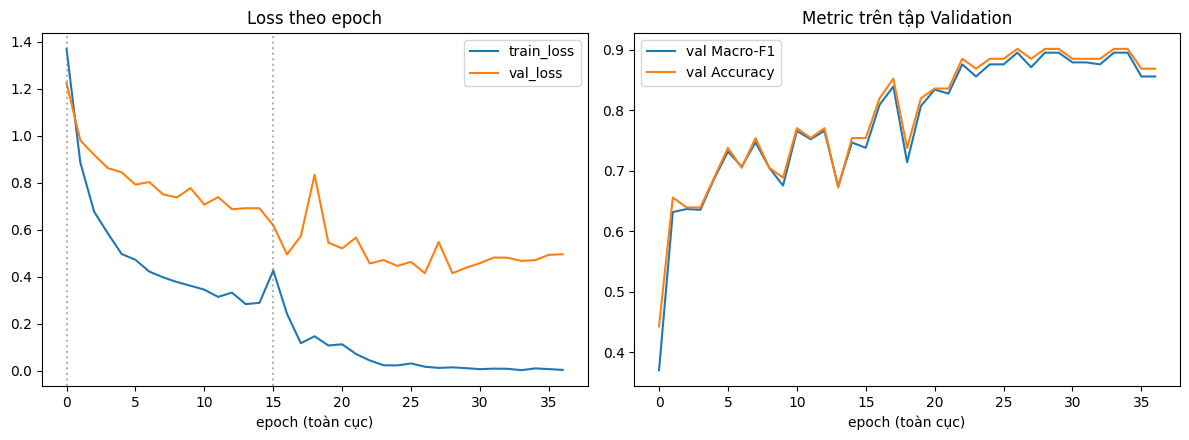

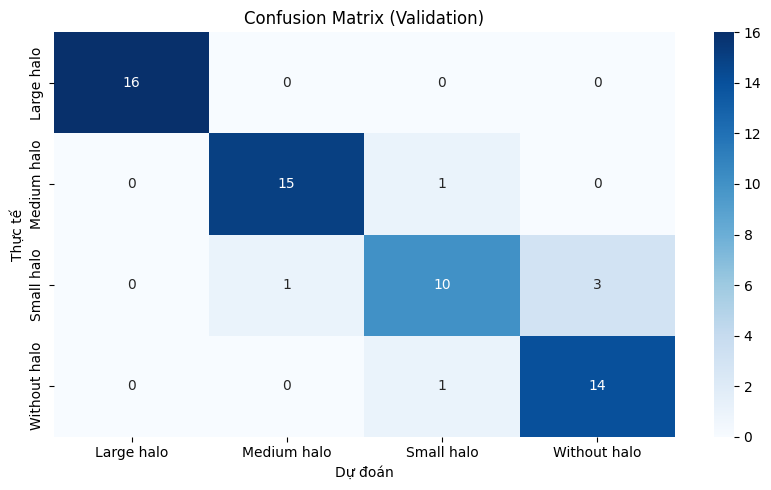

              precision    recall  f1-score   support

  Large halo       1.00      1.00      1.00        16
 Medium halo       0.94      0.94      0.94        16
  Small halo       0.83      0.71      0.77        14
Without halo       0.82      0.93      0.88        15

    accuracy                           0.90        61
   macro avg       0.90      0.90      0.90        61
weighted avg       0.90      0.90      0.90        61

☁️  Đã lưu toàn bộ output của 'vit_base' vào: /content/drive/MyDrive/SpermAI_Benchmark/outputs/TaskB/vit_base

✅ HOÀN TẤT MODEL 'vit_base'.
   Khi đã train xong toàn bộ 6 model của Task B, hãy mở notebook `Evaluation.ipynb` để đánh giá trên tập TEST.

🎉 ĐÃ HOÀN TẤT TRAIN TOÀN BỘ MODEL.


In [24]:
if __name__ == "__main__":
    # ================= ĐIỀU CHỈNH CÁC THÔNG SỐ NÀY =================
    MODEL_TO_RUN = "vit_base"   # "resnet50" | "convnext_base" | "efficientnetv2_m"
                             # | "swin_base" | "vit_base" | "dinov2" | "ALL"
    STAGE1_EPOCHS, STAGE1_PATIENCE = 15, 6
    STAGE2_EPOCHS, STAGE2_PATIENCE = 50, 10

    # Với model linear-probing (dinov2), chỉ Stage 1 chạy -> có thể cho epoch/patience lớn hơn
    DINOV2_STAGE1_EPOCHS, DINOV2_STAGE1_PATIENCE = 40, 10
    # =================================================================

    if MODEL_TO_RUN == "ALL":
        MODELS_TO_RUN = list(MODEL_CONFIGS.keys())
    else:
        assert MODEL_TO_RUN in MODEL_CONFIGS, f"Model '{MODEL_TO_RUN}' chưa được cấu hình trong MODEL_CONFIGS."
        MODELS_TO_RUN = [MODEL_TO_RUN]

    for MODEL_TO_RUN in MODELS_TO_RUN:

        print("\n" + "=" * 80)
        print(f"🚀 BẮT ĐẦU TRAIN MODEL: {MODEL_TO_RUN}")
        print("=" * 80)

        # Chọn thông số train theo strategy của từng model
        if MODEL_CONFIGS.get(MODEL_TO_RUN, {}).get("strategy") == "linear_probe":
            # DINOv2: chỉ chạy Stage 1
            current_stage1_epochs = DINOV2_STAGE1_EPOCHS
            current_stage1_patience = DINOV2_STAGE1_PATIENCE
            current_stage2_epochs = 0
            current_stage2_patience = 0
        else:
            # Các model two-stage: dùng đúng thông số đã chỉnh ở đầu cell
            current_stage1_epochs = STAGE1_EPOCHS
            current_stage1_patience = STAGE1_PATIENCE
            current_stage2_epochs = STAGE2_EPOCHS
            current_stage2_patience = STAGE2_PATIENCE

        existing_ckpt = os.path.join(OUTPUT_DRIVE_DIR, MODEL_TO_RUN, "best_model.pth")
        if os.path.exists(existing_ckpt):
            print(f"⚠️  Model '{MODEL_TO_RUN}' đã có checkpoint trên Drive:\n   {existing_ckpt}")
            print("   Chạy tiếp sẽ GHI ĐÈ kết quả cũ. Đổi MODEL_TO_RUN nếu không muốn ghi đè.\n")

        model, history_df, best_val_f1 = train_model(
            model_key=MODEL_TO_RUN,
            num_classes=len(CLASSES),
            class_to_idx=class_to_idx,
            train_list=train_list,
            val_list=val_list,
            stage1_epochs=STAGE1_EPOCHS, stage1_patience=STAGE1_PATIENCE,
            stage2_epochs=STAGE2_EPOCHS, stage2_patience=STAGE2_PATIENCE,
            strategy=MODEL_CONFIGS[MODEL_TO_RUN].get("strategy", "two_stage"),
        )

        val_tf = build_transforms(model, augment=False)
        val_loader_final = DataLoader(SpermDataset(val_list, class_to_idx, val_tf),
                                       batch_size=MODEL_CONFIGS[MODEL_TO_RUN]["batch_size"], shuffle=False)
        val_metrics, val_preds, val_labels = evaluate(model, val_loader_final, nn.CrossEntropyLoss(), device)
        print("\n📊 KẾT QUẢ VALIDATION CUỐI CÙNG:", {k: round(v, 4) for k, v in val_metrics.items()})

        out_dir = save_run_outputs(
            MODEL_TO_RUN, model, history_df, val_metrics, val_preds, val_labels,
            CLASSES, class_to_idx, extra_config={"best_val_f1_macro": best_val_f1}
        )

        print(f"\n✅ HOÀN TẤT MODEL '{MODEL_TO_RUN}'.")
        print("   Khi đã train xong toàn bộ 6 model của Task B, hãy mở notebook `Evaluation.ipynb` để đánh giá trên tập TEST.")

    print("\n" + "=" * 80)
    print("🎉 ĐÃ HOÀN TẤT TRAIN TOÀN BỘ MODEL.")
    print("=" * 80)